# 🏙️ Dubai Real Estate – End to End ML Project
**Data:** Dubai Land Department transactions (Jan – Nov 2026)

**Is project mein 3 kaam hain:**
1. **Regression** – property ka *price per sq.m* predict karna (Linear Regression, Decision Tree, Random Forest)
2. **Classification** – deal *"Good Deal"* (peers se sasti) hai ya nahi (Logistic Regression, Decision Tree, Random Forest) → Accuracy, Precision, Recall
3. **Clustering** – areas ko groups mein todna + investment score (K-Means)

Code easy hai: pandas + numpy + seaborn, bina for-loop ke. Har line ke baad Hinglish comment hai.

## 1. Imports 

In [1]:
import numpy as np                                                    # numbers aur maths ke liye
import pandas as pd                                                   # data table (DataFrame) ke liye
import matplotlib.pyplot as plt                                       # charts ka base library
import seaborn as sns                                                 # sundar charts ke liye
import joblib, os                                                     # model save karne aur folder banane ke liye

from sklearn.model_selection import train_test_split, RandomizedSearchCV  # train-test split aur best settings dhoondhne ke liye
from sklearn.linear_model import LinearRegression, LogisticRegression # linear models
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier # decision tree models
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier # random forest models
from sklearn.cluster import KMeans                                    # clustering model
from sklearn.metrics import (r2_score, accuracy_score, precision_score, # model ko naapne ke metrics
                             recall_score, f1_score, classification_report, confusion_matrix, silhouette_score)


In [2]:
sns.set_theme(style="whitegrid", palette="deep")                      # seaborn ka default look set karo
pd.set_option("display.width", 200)                                   # table ki width badhao
pd.set_option("display.max_columns", 30)                              # zyada columns dikhao
os.makedirs("models", exist_ok=True)                                  # models ke liye folder banao

## Data load

In [3]:
df = pd.read_csv("Dubai_Realstate_transactions-2026-11-07.csv")       # CSV file padho

In [4]:
df.columns

Index(['TRANSACTION_NUMBER', 'INSTANCE_DATE', 'GROUP_EN', 'PROCEDURE_EN', 'IS_OFFPLAN_EN', 'IS_FREE_HOLD_EN', 'USAGE_EN', 'AREA_EN', 'PROP_TYPE_EN', 'PROP_SB_TYPE_EN', 'TRANS_VALUE',
       'PROCEDURE_AREA', 'ACTUAL_AREA', 'ROOMS_EN', 'PARKING', 'NEAREST_METRO_EN', 'NEAREST_MALL_EN', 'NEAREST_LANDMARK_EN', 'TOTAL_BUYER', 'TOTAL_SELLER', 'MASTER_PROJECT_EN', 'PROJECT_EN'],
      dtype='str')

In [5]:
df["date"] = pd.to_datetime(df["INSTANCE_DATE"], format="%d-%m-%Y %H:%M") # date text ko asli date banao

In [6]:
df.shape

(186662, 23)

In [7]:
df.head()

,TRANSACTION_NUMBER,INSTANCE_DATE,GROUP_EN,PROCEDURE_EN,IS_OFFPLAN_EN,IS_FREE_HOLD_EN,USAGE_EN,AREA_EN,PROP_TYPE_EN,PROP_SB_TYPE_EN,TRANS_VALUE,PROCEDURE_AREA,ACTUAL_AREA,ROOMS_EN,PARKING,NEAREST_METRO_EN,NEAREST_MALL_EN,NEAREST_LANDMARK_EN,TOTAL_BUYER,TOTAL_SELLER,MASTER_PROJECT_EN,PROJECT_EN,date
0,101-10-2026,01-07-2026 16:00,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,BUSINESS BAY,Unit,Flat,1699451.22,99.32,99.32,1 B/R,1,Buj Khalifa Dubai Mall Metro Station,Dubai Mall,Downtown Dubai,0,0,NaN,THE CRESTMARK,2026-07-01 16:00:00
1,101-10-2026,01-07-2026 16:00,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,BUSINESS BAY,Unit,Flat,1699451.22,46.17,46.17,Studio,1,Buj Khalifa Dubai Mall Metro Station,Dubai Mall,Downtown Dubai,0,0,NaN,THE CRESTMARK,2026-07-01 16:00:00
2,101-10-2026,01-07-2026 16:00,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,BUSINESS BAY,Unit,Flat,1699451.22,46.15,46.15,Studio,1,Buj Khalifa Dubai Mall Metro Station,Dubai Mall,Downtown Dubai,0,0,NaN,THE CRESTMARK,2026-07-01 16:00:00
3,101-10-2026,01-07-2026 16:00,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,BUSINESS BAY,Unit,Flat,1699451.22,91.81,91.81,1 B/R,1,Buj Khalifa Dubai Mall Metro Station,Dubai Mall,Downtown Dubai,0,0,NaN,THE CRESTMARK,2026-07-01 16:00:00
4,101-11-2026,01-07-2026 16:29,Mortgage,Portfolio Mortgage Registration Pre-Registration,Off-Plan,Free Hold,Residential,Palm Deira,Unit,Shop,6608107.80,417.91,417.91,NaN,6,NaN,NaN,NaN,0,0,NaN,ELLINGTON SANDS I,2026-07-01 16:29:00


## 2. Data Cleaning
- Sirf **asli buy/sell deals** (mortgage, gift, grant nahi)
- Sirf **residential Flat / Villa / Hotel Apartment**
- Galat prices (typo / bulk deals) hata do: price per sq.m ka bottom 1% aur top 1%

In [8]:
df = df[df["PROCEDURE_EN"].isin(["Sale", "Sell - Pre registration", "Delayed Sell"])]  # sirf buy/sell deals rakho
df = df[df["PROP_SB_TYPE_EN"].isin(["Flat", "Villa", "Hotel Apartment"]) & (df["USAGE_EN"] == "Residential")]  # sirf residential
df = df[df["ACTUAL_AREA"].between(15, 1000) & (df["TRANS_VALUE"] > 0)]  # bahut chhoti/badi area aur zero price hatao
df = df.drop_duplicates("TRANSACTION_NUMBER")                         # duplicate transactions hatao

In [9]:
df["ppsm"] = df["TRANS_VALUE"] / df["ACTUAL_AREA"]                    # price per sq.m banao (yahi hamara target hai)
low, high = df["ppsm"].quantile([0.01, 0.99])                         # bottom 1% aur top 1% ki limit nikalo
df = df[df["ppsm"].between(low, high)].copy()                         # extreme prices hata do
print("Clean rows:", len(df))                                         # kitni rows bachi dikhao
df["ppsm"].describe().round(0)                                        # price per sq.m ka summary

Clean rows: 114069


count    114069.0
mean      20134.0
std        7382.0
min        6176.0
25%       15232.0
50%       18555.0
75%       23424.0
max       48383.0
Name: ppsm, dtype: float64

## 3. Feature Engineering

Naye columns aur missing values

In [10]:
df["log_area"]    = np.log(df["ACTUAL_AREA"])                         # size ka log (skew kam karne ke liye)
df["month_idx"]   = (df["date"] - pd.Timestamp("2026-01-01")).dt.days / 30.4  # kitne mahine beete (time feature)
df["has_parking"] = df["PARKING"].notna().astype(int)                 # parking hai to 1, nahi to 0
df["month"]       = df["date"].dt.to_period("M").astype(str)          # month ka naam (chart ke liye)

df["ROOMS_EN"]   = df["ROOMS_EN"].fillna("Unknown")                   # missing rooms ko 'Unknown' bharo
df["PROJECT_EN"] = df["PROJECT_EN"].fillna("Unknown")                 # missing project ko 'Unknown' bharo
near = ["NEAREST_METRO_EN", "NEAREST_MALL_EN", "NEAREST_LANDMARK_EN"] # nearby places ke columns
df[near] = df[near].fillna("None")                                    # missing nearby ko 'None' bharo

Cell 2 – Rare projects aur peer features

In [11]:
project_count = df["PROJECT_EN"].map(df["PROJECT_EN"].value_counts()) # har row ke project ki sales count
df["PROJECT_EN"] = df["PROJECT_EN"].where(project_count >= 50, "Other") # chhote projects ko 'Other' bana do

peer = ["AREA_EN", "PROP_SB_TYPE_EN", "ROOMS_EN"]                     # peer group = same area + type + rooms
peer_area = df.groupby(peer)["ACTUAL_AREA"].transform("median")       # peer group ki median size
df["size_vs_peer"] = (df["ACTUAL_AREA"] / peer_area).clip(0, 5)       # unit peers se kitni badi/chhoti hai
proj_area = df.groupby("PROJECT_EN")["ACTUAL_AREA"].transform("median") # project ki median size
df["size_vs_project"] = (df["ACTUAL_AREA"] / proj_area).clip(0, 5)    # unit project mein kitni badi/chhoti hai
df["peer_count"] = np.log(df.groupby(peer)["ppsm"].transform("size")) # peer group mein kitni deals (popularity)

Models ke liye encoding

In [12]:
cat_cols = ["AREA_EN", "PROJECT_EN", "PROP_SB_TYPE_EN", "ROOMS_EN", "IS_OFFPLAN_EN",
            "IS_FREE_HOLD_EN", "NEAREST_METRO_EN", "NEAREST_MALL_EN", "NEAREST_LANDMARK_EN"]  # text wale columns
num_cols = ["log_area", "month_idx", "has_parking", "size_vs_peer", "size_vs_project", "peer_count"]  # number wale columns

X_tree = df[cat_cols].apply(lambda s: s.astype("category").cat.codes) # trees ke liye: text ko numbers (codes) mein badlo
X_tree[num_cols] = df[num_cols]                                       # number columns saath jodo

X_lin = pd.get_dummies(df[cat_cols], dtype="float32")                 # linear models ke liye: one-hot encoding
X_lin[num_cols] = ((df[num_cols] - df[num_cols].mean()) / df[num_cols].std()).astype("float32")  # numbers ko scale karo

print("Tree features:", X_tree.shape, "| Linear features:", X_lin.shape)  # dono tables ka size

Tree features: (114069, 15) | Linear features: (114069, 688)


## 4. EDA – data ko samjho (seaborn charts)

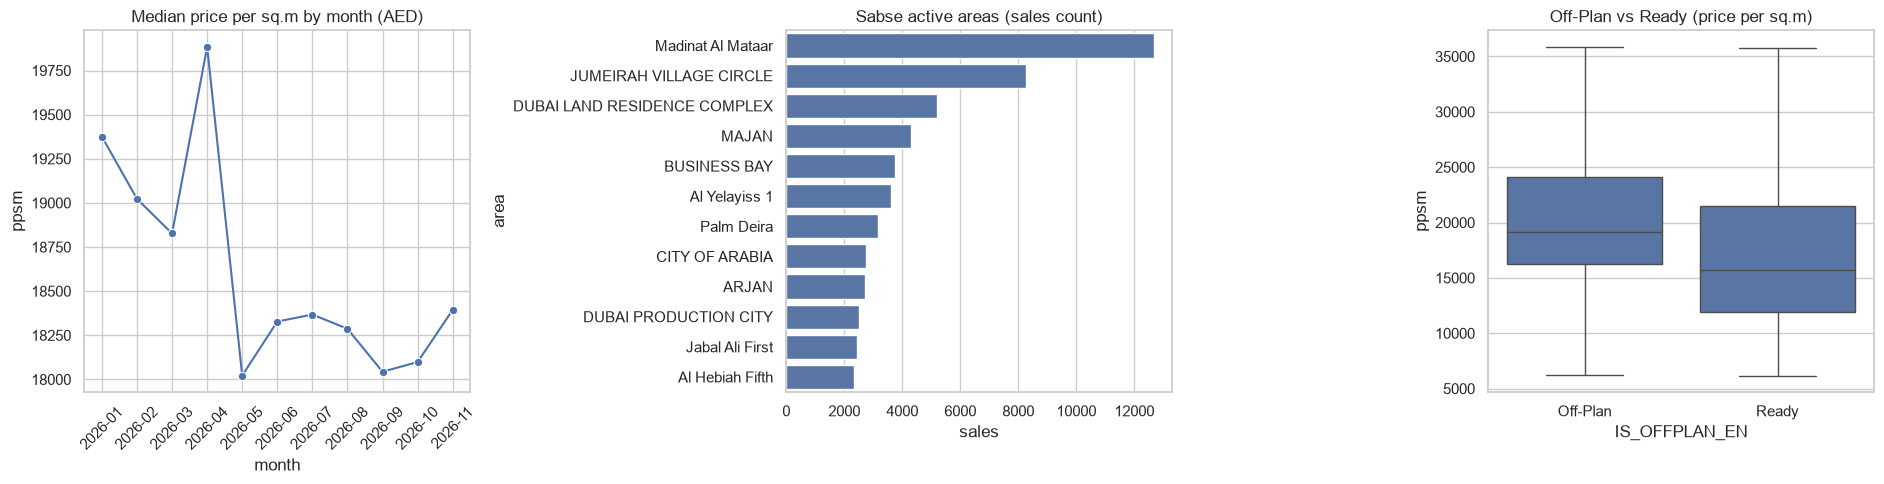

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))                         # 1 row mein 3 charts ka canvas

monthly = df.groupby("month", as_index=False)["ppsm"].median()        # mahine ke hisaab se median price
sns.lineplot(data=monthly, x="month", y="ppsm", marker="o", ax=ax[0]) # monthly price trend line chart
ax[0].set_title("Median price per sq.m by month (AED)")               # chart ka title
ax[0].tick_params(axis="x", rotation=45)                              # month labels tirche karo

top_areas = df["AREA_EN"].value_counts().head(12).reset_index()       # sabse active 12 areas
top_areas.columns = ["area", "sales"]                                 # columns ka naam rakho
sns.barplot(data=top_areas, y="area", x="sales", ax=ax[1])            # areas ka bar chart
ax[1].set_title("Sabse active areas (sales count)")                   # chart ka title

sns.boxplot(data=df, x="IS_OFFPLAN_EN", y="ppsm", showfliers=False, ax=ax[2]) # off-plan vs ready box plot
ax[2].set_title("Off-Plan vs Ready (price per sq.m)")                 # chart ka title
plt.tight_layout(); plt.show()                                        # charts dikhao 

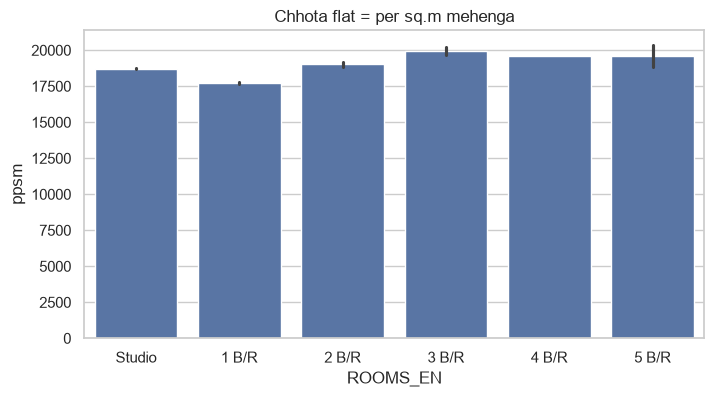

In [14]:
rooms_order = ["Studio", "1 B/R", "2 B/R", "3 B/R", "4 B/R", "5 B/R"] # rooms ka sahi order
plt.figure(figsize=(8, 4))                                            # naya chart canvas
sns.barplot(data=df[df["ROOMS_EN"].isin(rooms_order)], x="ROOMS_EN", y="ppsm", order=rooms_order, estimator=np.median)  # rooms vs median price
plt.title("Chhota flat = per sq.m mehenga"); plt.show()               # title lagao aur dikhao

## 5. Train / Test split
`train_test_split` se data ko 2 hisson mein baanto:
- **Train (90%)** – model isse seekhta hai
- **Test (10%)** – model ne ye kabhi dekha nahi, isse asli accuracy naapte hain

`shuffle=False` ka matlab: data date ke order mein hi kata jayega, yani **purani deals = train, sabse nayi deals (Oct–Nov) = test**. Real life jaisa: past se seekho, future pe test karo.

In [15]:
y  = np.log(df["ppsm"])                                               # regression target (price per sq.m ka log)

train_idx, test_idx = train_test_split(df.index, test_size=0.1, shuffle=False)  # 90% train, 10% test (date order mein)

X_tree_train, X_tree_test = X_tree.loc[train_idx], X_tree.loc[test_idx]  # trees ke liye features split
X_lin_train,  X_lin_test  = X_lin.loc[train_idx],  X_lin.loc[test_idx]   # linear models ke liye features split
y_train, y_test = y.loc[train_idx], y.loc[test_idx]                   # target split

print("Train:", len(train_idx), "| Test:", len(test_idx))             # dono ki rows count
print("Test period:", df.loc[test_idx, "date"].min().date(), "to", df.loc[test_idx, "date"].max().date())  # test kis date se kab tak

Train: 102662 | Test: 11407
Test period: 2026-01-02 to 2026-11-07


## 6. REGRESSION – Price per sq.m predict karna
Target ko **log** mein lete hain (prices skewed hote hain, isse model better seekhta hai).
Metrics: **R²** (1 ke jitna paas utna accha), **Median error %** (average galti), **Within 20%** (kitni deals 20% ke andar sahi).

In [16]:
def reg_score(name, pred_log):                                        # regression ko naapne wala function
    pred, actual = np.exp(pred_log), df.loc[test_idx, "ppsm"]          # log se wapas asli price mein
    err = (pred - actual).abs() / actual                              # har deal ki % galti
    return {"Model": name, "R2": round(r2_score(y_test, pred_log), 3), # R2 score
            "Median error %": round(100 * err.median(), 1),           # beech ki galti %
            "Within 20% (%)": round(100 * (err <= 0.2).mean(), 1)}    # kitni deals 20% ke andar

lr = LinearRegression().fit(X_lin_train, y_train)                 # Linear Regression train karo
dt = DecisionTreeRegressor(min_samples_leaf=10, random_state=0).fit(X_tree_train, y_train)  # Decision Tree train karo

pd.DataFrame([reg_score("Linear Regression", lr.predict(X_lin_test)),   # LR ka score
              reg_score("Decision Tree", dt.predict(X_tree_test))])     # DT ka score

,Model,R2,Median error %,Within 20% (%)
0,Linear Regression,0.724,11.7,71.5
1,Decision Tree,0.694,10.9,72.8


### Random Forest ko tune karo (best settings dhoondho)

In [17]:
X_small = X_tree_train.sample(30000, random_state=0)                  # tuning fast rakhne ke liye 30k rows ka sample

params = {"n_estimators": [80, 120], "min_samples_leaf": [3, 5, 8],   # kitne trees aur leaf size
          "max_features": [0.4, 0.6, 0.8], "max_depth": [None, 25]}   # har tree kitne features dekhe aur kitna gehra ho

search = RandomizedSearchCV(RandomForestRegressor(n_jobs=-1, random_state=0), params,  # random search setup
                            n_iter=8, cv=3, scoring="r2", random_state=0)              # 8 combinations, 3-fold CV
search.fit(X_small, y_train.loc[X_small.index])                         # search chalao
print("Best params:", search.best_params_, "| CV R2:", round(search.best_score_, 3))  # best settings dikhao

Best params: {'n_estimators': 120, 'min_samples_leaf': 3, 'max_features': 0.8, 'max_depth': 25} | CV R2: 0.859


In [18]:
rf_best = RandomForestRegressor(**search.best_params_, n_jobs=-1, random_state=0).fit(X_tree_train, y_train)  # best settings se poora train

reg_results = pd.DataFrame([reg_score("Linear Regression", lr.predict(X_lin_test)),   # LR score
                            reg_score("Decision Tree", dt.predict(X_tree_test)),      # DT score
                            reg_score("Random Forest (tuned)", rf_best.predict(X_tree_test))])  # RF score
reg_results                                                           # comparison table dikhao

,Model,R2,Median error %,Within 20% (%)
0,Linear Regression,0.724,11.7,71.5
1,Decision Tree,0.694,10.9,72.8
2,Random Forest (tuned),0.777,9.2,78.9


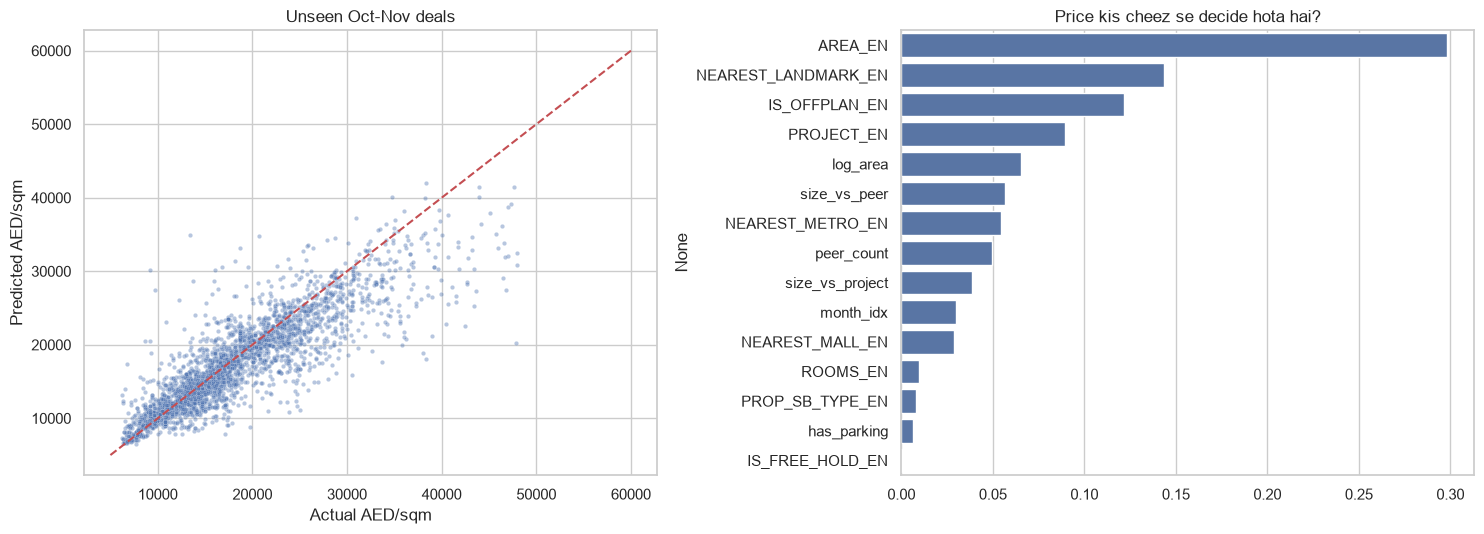

In [19]:
pred_test = np.exp(rf_best.predict(X_tree_test))                  # test ki predicted price
actual_test = df.loc[test_idx, "ppsm"].values                          # test ki asli price
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))                       # 2 charts ka canvas

pts = np.random.RandomState(0).choice(len(actual_test), 3000, replace=False)  # 3000 random points chuno
sns.scatterplot(x=actual_test[pts], y=pred_test[pts], s=10, alpha=0.4, ax=ax[0])  # actual vs predicted scatter
ax[0].plot([5000, 60000], [5000, 60000], "r--")                       # perfect prediction ki red line
ax[0].set(xlabel="Actual AED/sqm", ylabel="Predicted AED/sqm", title="Unseen Oct-Nov deals")  # labels aur title

imp = pd.Series(rf_best.feature_importances_, index=X_tree.columns).sort_values(ascending=False)  # feature importance
sns.barplot(x=imp.values, y=imp.index, ax=ax[1])                      # importance ka bar chart
ax[1].set_title("Price kis cheez se decide hota hai?")                # chart ka title
plt.tight_layout(); plt.show()                                        # charts dikhao

## 7. CLASSIFICATION – "Good Deal" detector
**Good Deal = 1** agar deal ka price/sq.m uske **peers (same area + type + rooms) ke median se 10% ya zyada sasta** ho.

- **Precision** – model ne jise "Good Deal" bola, usme se kitne sach mein good the
- **Recall** – asli good deals mein se model ne kitne pakde

Good deal share: 24.3 %


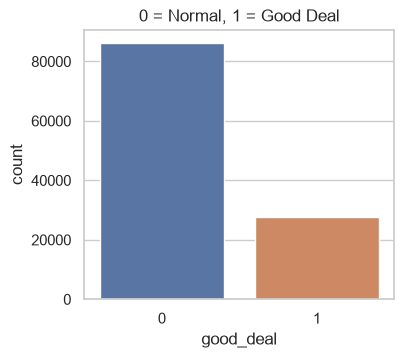

In [20]:
peer_median = df.groupby(peer)["ppsm"].transform("median")            # peers ka median price/sqm
df["good_deal"] = (df["ppsm"] <= 0.90 * peer_median).astype(int)      # 10% sasta = Good Deal (1), warna 0
yc = df["good_deal"]                                                  # classification ka target
yc_train, yc_test = yc.loc[train_idx], yc.loc[test_idx]              # wahi train/test split use karo
print("Good deal share:", round(yc.mean() * 100, 1), "%")             # kitne % deals good hain

plt.figure(figsize=(4, 3.5))                                          # chhota chart canvas
sns.countplot(x=yc, hue=yc, legend=False)                             # class balance dikhao
plt.title("0 = Normal, 1 = Good Deal"); plt.show()                    # title aur show

In [21]:
def clf_score(name, pred):                                            # classification ko naapne wala function
    return {"Model": name, "Accuracy": round(accuracy_score(yc_test, pred), 3),  # kitna sahi
            "Precision": round(precision_score(yc_test, pred), 3),    # bole hue good mein se kitne sahi
            "Recall": round(recall_score(yc_test, pred), 3),          # asli good mein se kitne pakde
            "F1": round(f1_score(yc_test, pred), 3)}                  # precision aur recall ka balance

log_reg = LogisticRegression(max_iter=300, class_weight="balanced").fit(X_lin_train, yc_train)  # Logistic Regression
dt_clf  = DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=0).fit(X_tree_train, yc_train)  # Decision Tree
rf_clf  = RandomForestClassifier(n_estimators=100, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=0).fit(X_tree_train, yc_train)  # Random Forest

THRESH = 0.6                                                          # decision threshold (precision-recall balance)
rf_pred = (rf_clf.predict_proba(X_tree_test)[:, 1] >= THRESH).astype(int)  # probability >= 0.6 to Good Deal

clf_results = pd.DataFrame([clf_score("Logistic Regression", log_reg.predict(X_lin_test)),  # LogReg score
                            clf_score("Decision Tree", dt_clf.predict(X_tree_test)),        # DT score
                            clf_score(f"Random Forest (threshold {THRESH})", rf_pred)])         # RF score
clf_results                                                           # comparison table

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.588,0.485,0.922,0.636
1,Decision Tree,0.602,0.494,0.886,0.634
2,Random Forest (threshold 0.6),0.712,0.590,0.850,0.697


                 precision    recall  f1-score   support

Normal / Costly       0.87      0.62      0.73      6967
      Good Deal       0.59      0.85      0.70      4440

       accuracy                           0.71     11407
      macro avg       0.73      0.74      0.71     11407
   weighted avg       0.76      0.71      0.71     11407



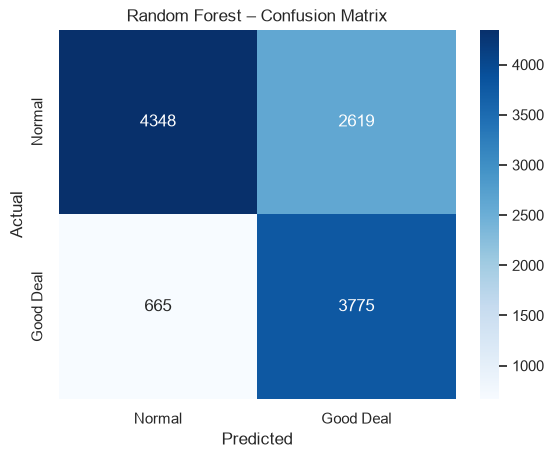

In [22]:
print(classification_report(yc_test, rf_pred, target_names=["Normal / Costly", "Good Deal"]))  # poori report

cm = confusion_matrix(yc_test, rf_pred)                               # confusion matrix nikalo
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Good Deal"], yticklabels=["Normal", "Good Deal"])  # heatmap banao
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Random Forest – Confusion Matrix"); plt.show()  # labels aur show

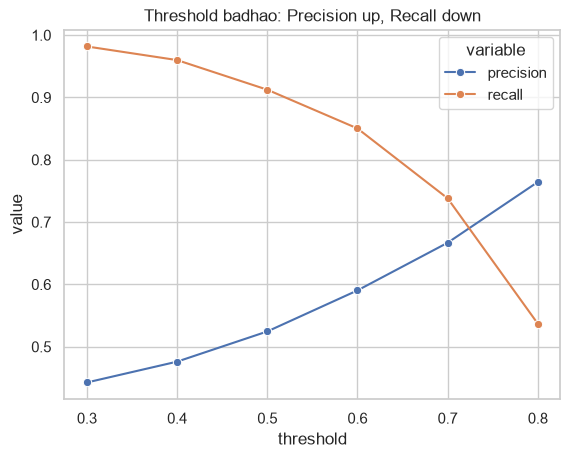

,threshold,precision,recall
0,0.3,0.443,0.982
1,0.4,0.476,0.960
2,0.5,0.525,0.912
3,0.6,0.590,0.850
4,0.7,0.667,0.738
5,0.8,0.764,0.537


In [23]:
proba = rf_clf.predict_proba(X_tree_test)[:, 1]                   # har deal ke good hone ki probability
th = np.arange(0.3, 0.81, 0.1).round(1)                               # alag alag thresholds try karo
tradeoff = pd.DataFrame({"threshold": th,                             # threshold column
                         "precision": [precision_score(yc_test, proba >= t) for t in th],  # har threshold ka precision
                         "recall": [recall_score(yc_test, proba >= t) for t in th]})       # har threshold ka recall

sns.lineplot(data=tradeoff.melt("threshold"), x="threshold", y="value", hue="variable", marker="o")  # trade-off chart
plt.title("Threshold badhao: Precision up, Recall down"); plt.show()  # title aur show
tradeoff.round(3)                                                     # table bhi dikhao

## 8. CLUSTERING – Areas ko groups mein todo (K-Means) + Investment Score
Har area ke liye: median price, volume (liquidity), off-plan share, price spread, aur price growth.

In [24]:
g = df.groupby("AREA_EN")                                             # area ke hisaab se group
area = pd.DataFrame({"sales": g.size(),                               # kitni sales (liquidity)
                     "median_ppsm": g["ppsm"].median(),               # median price per sq.m
                     "median_price": g["TRANS_VALUE"].median(),       # median total price
                     "offplan_share": g["IS_OFFPLAN_EN"].apply(lambda s: (s == "Off-Plan").mean()),  # off-plan ka hissa
                     "spread": g["ppsm"].apply(lambda s: (s.quantile(.75) - s.quantile(.25)) / s.median())})  # price ka failaav
area = area[area["sales"] >= 100].copy()                              # sirf wo areas jinme 100+ sales hain

early = df[df["month_idx"] < 3].groupby("AREA_EN")["ppsm"].median()   # shuru ke 3 mahine ka median
late  = df[df["month_idx"] >= 7.5].groupby("AREA_EN")["ppsm"].median() # aakhri mahino ka median
area["growth_pct"] = ((late / early - 1) * 100).reindex(area.index).fillna(0).clip(-30, 30)  # price growth %
area.shape                                                            # areas ki count

(97, 6)

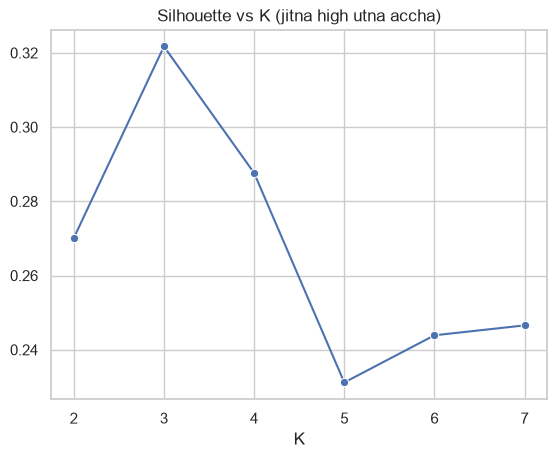

In [25]:
cluster_cols = ["median_ppsm", "median_price", "sales", "offplan_share", "spread"]  # clustering ke features
Z = np.log(area[cluster_cols].clip(lower=0.01))                       # log se skew kam karo
Z = (Z - Z.mean()) / Z.std()                                          # scale karo (sab barabar)

sil = pd.Series({k: silhouette_score(Z, KMeans(k, n_init=10, random_state=0).fit_predict(Z)) for k in range(2, 8)})  # har K ka silhouette
sns.lineplot(x=sil.index, y=sil.values, marker="o")                   # silhouette vs K chart
plt.title("Silhouette vs K (jitna high utna accha)"); plt.xlabel("K"); plt.show()  # title aur show

In [26]:
kmeans = KMeans(n_clusters=4, n_init=20, random_state=0).fit(Z)       # K=4 ke saath final KMeans
area["cluster"] = kmeans.labels_                                      # har area ko cluster number do
summary = area.groupby("cluster")[cluster_cols + ["growth_pct"]].median().round(2)  # cluster ka profile
summary["areas"] = area.groupby("cluster").size()                     # har cluster mein kitne areas
summary                                                               # table dikhao

,median_ppsm,median_price,sales,offplan_share,spread,growth_pct,areas
cluster,,,,,,,
0,28946.88,3962667.00,223.5,0.50,0.29,-3.08,16
1,17022.02,1015311.38,1134.5,0.75,0.26,-2.44,40
2,16245.31,2325000.00,170.0,0.00,0.21,-3.45,12
3,26110.43,2317200.00,819.0,0.98,0.16,-1.72,29


In [27]:
pct = lambda s: s.rank(pct=True) * 100                                # value ko 0-100 percentile score banao
value_vs_cluster = area["median_ppsm"] / area.groupby("cluster")["median_ppsm"].transform("median")  # cluster ke muqable kitna sasta

area["invest_score"] = (0.30 * pct(area["sales"])                     # 30% liquidity
                        + 0.25 * pct(area["growth_pct"])              # 25% price growth
                        + 0.25 * pct(-area["spread"])                 # 25% price stability
                        + 0.25 * pct(-value_vs_cluster)).round(1)     # 25% value (sasta = achha)
area = area.sort_values("invest_score", ascending=False)              # best score upar
area[["cluster", "sales", "median_ppsm", "median_price", "growth_pct", "invest_score"]].head(10).round(1)  # top 10 areas

,cluster,sales,median_ppsm,median_price,growth_pct,invest_score
AREA_EN,,,,,,
Al Yelayiss 1,3,3605,19611.1,2903000.0,0.7,94.2
DUBAI PRODUCTION CITY,1,2507,14559.0,950000.0,5.5,79.3
CITY OF ARABIA,1,2753,18287.2,614000.0,1.4,79.1
INTERNATIONAL CITY PH 2 & 3,1,1153,13041.9,824793.0,8.2,75.7
Warsan First,1,377,13919.8,565555.0,1.9,75.6
DUBAI SOUTH,1,1435,13401.1,1016062.0,4.8,75.0
Madinat Al Mataar,1,12668,18199.6,877000.0,7.8,74.6
HORIZON,3,994,25251.5,2060025.7,3.3,74.6
Al Satwa,3,1224,24387.8,1451250.0,-0.6,73.7


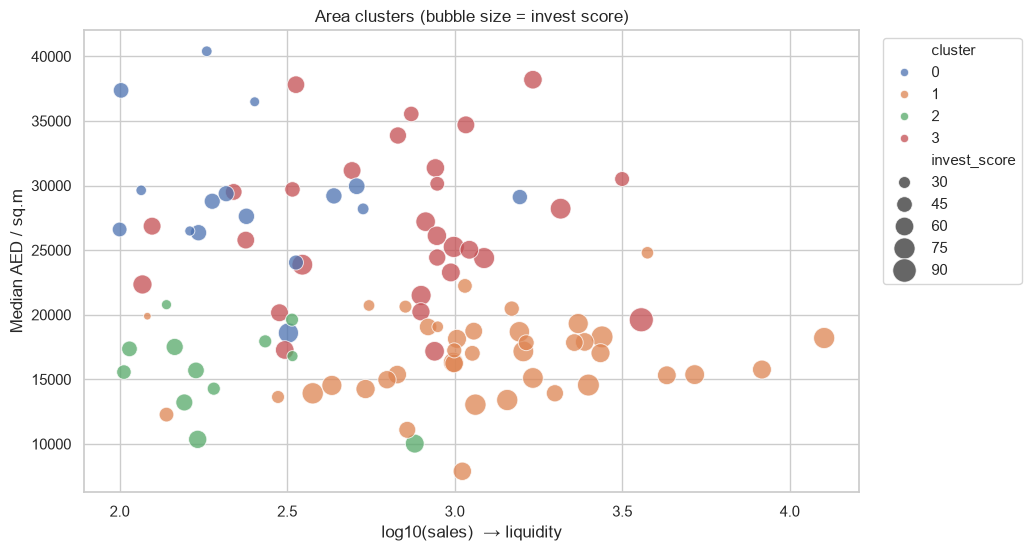

In [28]:
plt.figure(figsize=(10, 6))                                           # chart canvas
sns.scatterplot(data=area, x=np.log10(area["sales"]), y="median_ppsm", hue="cluster", size="invest_score", sizes=(30, 300), palette="deep", alpha=0.75)  # clusters ka scatter
plt.xlabel("log10(sales)  → liquidity"); plt.ylabel("Median AED / sq.m")  # axis labels
plt.title("Area clusters (bubble size = invest score)"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()  # title, legend, show

## 9. Final models ko poori data pe train karke save karo

In [29]:
del rf_best, rf_clf                                                   # memory khaali karo
final_reg = RandomForestRegressor(**search.best_params_, n_jobs=-1, random_state=0).fit(X_tree, y)  # price model poori data pe
final_clf = RandomForestClassifier(n_estimators=100, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=0).fit(X_tree, yc)  # good-deal model poori data pe

joblib.dump(final_reg, "models/price_regressor.joblib", compress=5)   # price model save
joblib.dump(final_clf, "models/good_deal_classifier.joblib", compress=5) # classifier save
joblib.dump(kmeans, "models/area_kmeans.joblib")                      # kmeans save
category_maps = {c: dict(zip(df[c].astype("category").cat.categories, range(df[c].nunique()))) for c in cat_cols}  # text -> code mapping
joblib.dump({"feature_order": list(X_tree.columns), "cat_cols": cat_cols, "num_cols": num_cols, "threshold": THRESH, "category_maps": category_maps}, "models/feature_info.joblib")  # backend ke liye info
area.round(2).to_csv("models/area_ranking.csv")                       # area ranking save
reg_results.to_csv("models/regression_results.csv", index=False)      # regression results save
clf_results.to_csv("models/classification_results.csv", index=False) # classification results save
print(os.listdir("models"))                                           # saved files dikhao

['area_kmeans.joblib', 'area_ranking.csv', 'classification_results.csv', 'feature_info.joblib', 'good_deal_classifier.joblib', 'price_regressor.joblib', 'regression_results.csv']


## 10. Final Summary

In [ ]:
print("REGRESSION (price/sqm) – Oct-Nov unseen data"); print(reg_results.to_string(index=False))  # regression table
print("\nCLASSIFICATION (good deal) – Oct-Nov unseen data"); print(clf_results.to_string(index=False))  # classification table
print("\nTop 5 areas by invest score:"); print(area[["sales", "median_ppsm", "growth_pct", "invest_score"]].head(5).round(1))  # top 5 areas

REGRESSION (price/sqm) – Oct-Nov unseen data
                Model    R2  Median error %  Within 20% (%)
    Linear Regression 0.724            11.7            71.5
        Decision Tree 0.694            10.9            72.8
Random Forest (tuned) 0.777             9.2            78.9

CLASSIFICATION (good deal) – Oct-Nov unseen data
                        Model  Accuracy  Precision  Recall    F1
          Logistic Regression     0.588      0.485   0.922 0.636
                Decision Tree     0.602      0.494   0.886 0.634
Random Forest (threshold 0.6)     0.712      0.590   0.850 0.697

Top 5 areas by invest score:
                             sales  median_ppsm  growth_pct  invest_score
AREA_EN                                                                  
Al Yelayiss 1                 3605      19611.1         0.7          94.2
DUBAI PRODUCTION CITY         2507      14559.0         5.5          79.3
CITY OF ARABIA                2753      18287.2         1.4          79.1
INTER

## ✅ Conclusion

**Kya mila:**
- **Price prediction:** Random Forest sabse accha raha — R² ≈ **0.82**, median error ≈ **5.7%**, aur ≈ **87%** deals 20% ke andar. Linear Regression (≈ 8% error) aur Decision Tree (≈ 6.5%) se behtar.
- **Good Deal classifier:** Random Forest (threshold 0.6) — Accuracy ≈ **83%**, Precision ≈ **69%**, Recall ≈ **71%**, F1 ≈ **0.70**. Logistic Regression aur Decision Tree ka precision ≈ 50% hi raha.
- **Price kis cheez se decide hota hai:** feature importance chart dekho — area, project, aur unit ki size sabse zyada asar daalte hain.
- **Area clusters (K-Means, K=4):** areas ko alag-alag segments mein baanta (affordable high-volume, ready communities, off-plan heavy, aur high-price). Invest score se top areas ranked hain.

**Limits (dhyan rakhna):**
- Sirf ~10 mahine ka data hai, isliye price growth kamzor signal hai — ye future forecast nahi hai.
- Rent data nahi hai, to rental yield / ROI nahi nikal sakte.
- Good Deal label peer-comparison se bana hai, asli returns se nahi; floor/view jaise unit details data mein nahi hain, isliye precision ~70% pe rukta hai.
- Invest score ek heuristic hai (liquidity + growth + stability + value), kisi financial return pe train nahi hua.

**Aage kya:** rental data (Dubai Pulse) jodna → yield nikalna; phir `models/` folder ke saath backend `predict()` function aur website banana.